Tieu Han TRAN - M2 MIAGE

# Statistical and Machine Learning
# Homework 2 : Uniform Convergence and the Limits of Learning

# Part I – Simulating Uniform Convergence

## Problème étudié
* Classe d'hypothèses finie : $\mathcal{H} = \{h_1, \dots, h_K\}$ de taille $\vert{}\mathcal{H}\vert{} = K < \infty$.
* True risk (erreur vraie) : Chaque hypothèse $h_j$ possède une erreur vraie fixée $L_\mathcal{D}(h_j) = p_j \in [0, 1]$.
* Nombre d'erreurs sur le training sample : Chaque exemple est mal classé par $h_j$ avec une probabilité $p_j$ (variable de Bernoulli de paramètre $p_j$). Le nombre total d'erreurs $E_j$ commises par $h_j$ sur les $m$ exemples suit donc une loi Binomiale :
$$E_j \sim \text{Binomial}(m, p_j)$$
* Empirical risk (erreur empirique) : C'est la proportion d'erreurs commises sur le training sample de taille $m$ :
$$L_S(h_j) = \frac{E_j}{m}$$

## 1. Empirical Risk as a Random Variable

Dans cette première question, on étudie le comportement de l'empirical error $L_S(h_j) = \frac{E_j}{m}$ en tant que variable aléatoire qui est autour du true error $L_\mathcal{D}(h_j) = p_j$.

### Choix et justification des paramètres expérimentaux :
* True errors des hypothèses ($p_1, \dots, p_K$) : On choisit $K = 5$ hypothèses ayant des true errors variés `p_tab = [0.05, 0.15, 0.25, 0.40, 0.70]` (allant d'une très bonne hypothèse qui se trompe $5\%$ du temps à une hypothèse qui fait du hasard à $70\%$). Pour l'étude détaillée sur une hypothèse fixée $h_j$, on sélectionne $p_j = 0.25$ car cette valeur permet d'observer une distribution bien symétrique sans être trop proche de 0 ou de 1.
* Tailles d'échantillon ($m$) : On choisit `m_tab = [10, 30, 50, 100, 250, 500, 1000]`. Ces tailles sont suffisamment variées pour observer la transition entre de très petits échantillons et de grands échantillons.
* Nombre de répétitions de Monte-Carlo : On fixe `N_REPETITIONS = 5000` tirages indépendants pour chaque taille $m$ afin que nos moyennes empiriques et nos histogrammes soient très précis.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

# Fixer le point de départ (seed) pour reproduire les expériences et avoir les mêmes résultats pour les interprétations
np.random.seed(0)

# Paramètres globaux pour la Partie I (Task 1)
# True errors p_1, ..., p_K choisies pour différentes hypothèses
p_tab = [
    0.05,
    0.15,
    0.25,
    0.40,
    0.70,
]

# Vraie erreur L_D(h_j) = p_j de l'hypothèse fixée h_j pour l'analyse
P_FIXE = (
    0.25  
)

# Différentes tailles du training sample m
m_tab = [
    10,
    30,
    50,
    100,
    250,
    500,
    1000,
]

# Nombre de répétitions de Monte-Carlo
N_REPETITIONS = 5000


def simuler_risque_empirique(m, p_j, n_rep=N_REPETITIONS):
  """Simule le risque empirique L_S(h_j) = E_j / m sur n_rep training samples de taille m.

  Entrées :
  - m (int) : Taille du training sample S.
  - p_j (float) : True risk L_D(h_j) de l'hypothèse h_j dans [0,1].
  - n_rep (int) : Nombre de simulations de Monte-Carlo.
  Retourne :
  - ls_tab (np.ndarray) : Tableau 1D de taille n_rep contenant les risques empiriques L_S(h_j) simulés.
  """
  # (a) Simulation du nombre d'erreurs E_j selon une loi Binomiale(m, p_j) répété n_rep fois
  ej_tab = np.random.binomial(n=m, p=p_j, size=n_rep)

  # (b) Calcul du risque empirique L_S(h_j) = E_j / m pour chaque répétition
  ls_tab = ej_tab / m
  return ls_tab


# Exécution des simulations pour l'hypothèse fixée (p_j = 0.25) pour chaque taille m
resultats_q1 = {}
print(
    f"Comparaison Moyenne Empirique vs Vrai Risque (p_j = {P_FIXE},"
    f" {N_REPETITIONS} répétitions) :\n"
)

for m in m_tab:
  ls_simules = simuler_risque_empirique(m, P_FIXE, N_REPETITIONS)
  moyenne_emp = np.mean(ls_simules)
  ecart_type_emp = np.std(ls_simules)
  # L'écart-type théorique d'une moyenne de Bernoulli est sqrt(p_j * (1 - p_j) / m)
  ecart_type_theo = np.sqrt(P_FIXE * (1.0 - P_FIXE) / m)

  resultats_q1[m] = (ls_simules, moyenne_emp, ecart_type_emp, ecart_type_theo)

  print(
      f"m = {m:4d} | Moyenne de L_S(h_j) = {moyenne_emp:.4f} (Vrai p_j ="
      f" {P_FIXE:.4f}) | Écart-type exp = {ecart_type_emp:.4f} (Théorique ="
      f" {ecart_type_theo:.4f})"
  )

# Vérification rapide sur les autres valeurs de p_1, ..., p_K pour m = 100
print(
    "\nVérification de l'espérance E[L_S(h_k)] = p_k pour les autres hypothèses"
    " (avec m = 100) :"
)
for idx, p_k in enumerate(p_tab):
  moy_k = np.mean(simuler_risque_empirique(100, p_k, N_REPETITIONS))
  print(
      f"Hypothèse h_{idx+1} : Vrai risque p_{idx+1} = {p_k:.2f} | Moyenne"
      f" empirique observée = {moy_k:.4f}"
  )

Comparaison Moyenne Empirique vs Vrai Risque (p_j = 0.25, 5000 répétitions) :

m =   10 | Moyenne de L_S(h_j) = 0.2493 (Vrai p_j = 0.2500) | Écart-type exp = 0.1370 (Théorique = 0.1369)
m =   30 | Moyenne de L_S(h_j) = 0.2486 (Vrai p_j = 0.2500) | Écart-type exp = 0.0795 (Théorique = 0.0791)
m =   50 | Moyenne de L_S(h_j) = 0.2480 (Vrai p_j = 0.2500) | Écart-type exp = 0.0609 (Théorique = 0.0612)
m =  100 | Moyenne de L_S(h_j) = 0.2501 (Vrai p_j = 0.2500) | Écart-type exp = 0.0446 (Théorique = 0.0433)
m =  250 | Moyenne de L_S(h_j) = 0.2491 (Vrai p_j = 0.2500) | Écart-type exp = 0.0271 (Théorique = 0.0274)
m =  500 | Moyenne de L_S(h_j) = 0.2498 (Vrai p_j = 0.2500) | Écart-type exp = 0.0194 (Théorique = 0.0194)
m = 1000 | Moyenne de L_S(h_j) = 0.2501 (Vrai p_j = 0.2500) | Écart-type exp = 0.0135 (Théorique = 0.0137)

Vérification de l'espérance E[L_S(h_k)] = p_k pour les autres hypothèses (avec m = 100) :
Hypothèse h_1 : Vrai risque p_1 = 0.05 | Moyenne empirique observée = 0.0499
Hypo

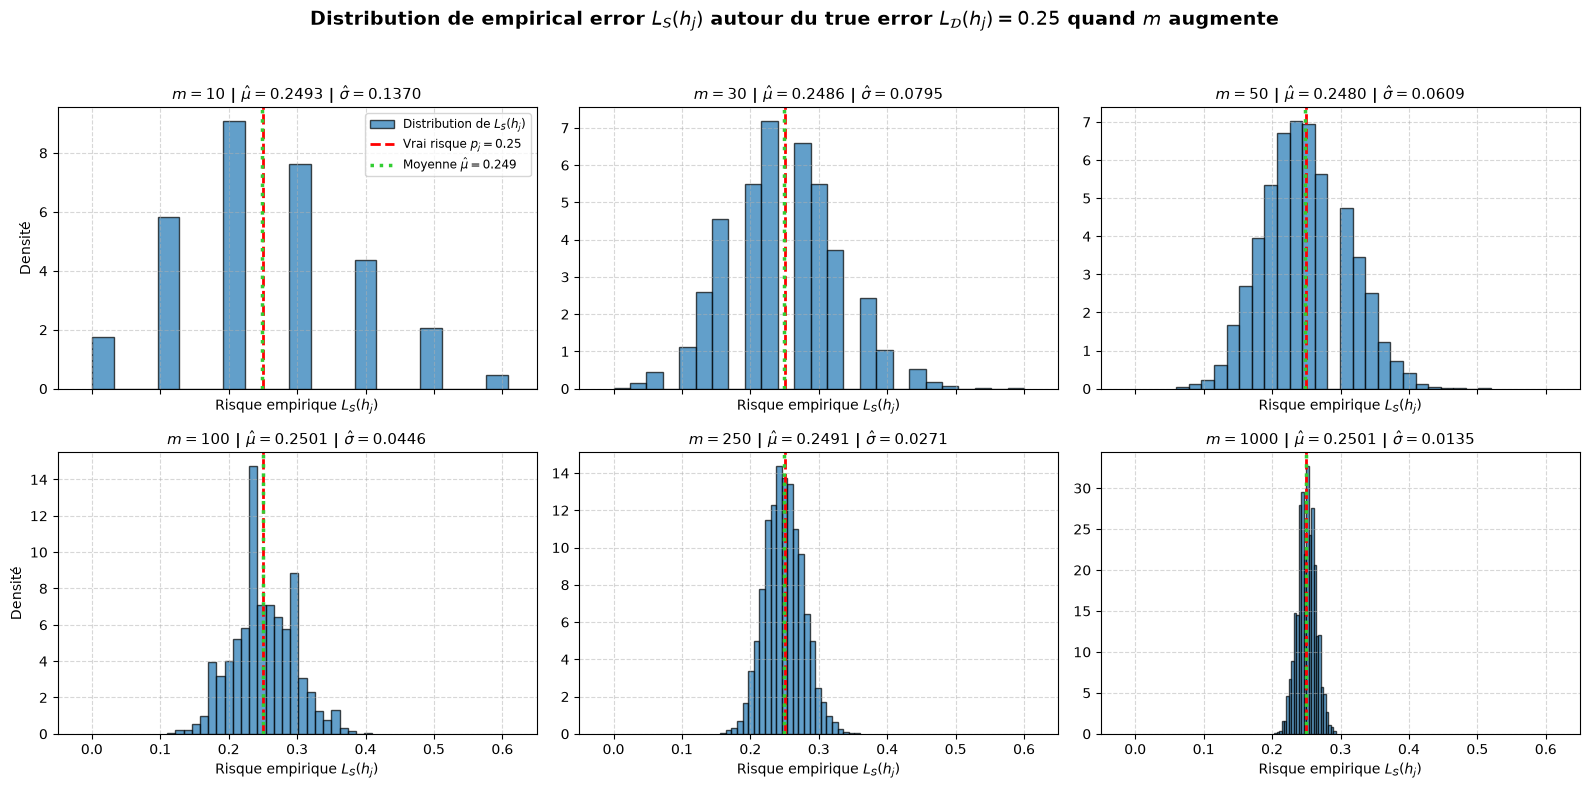

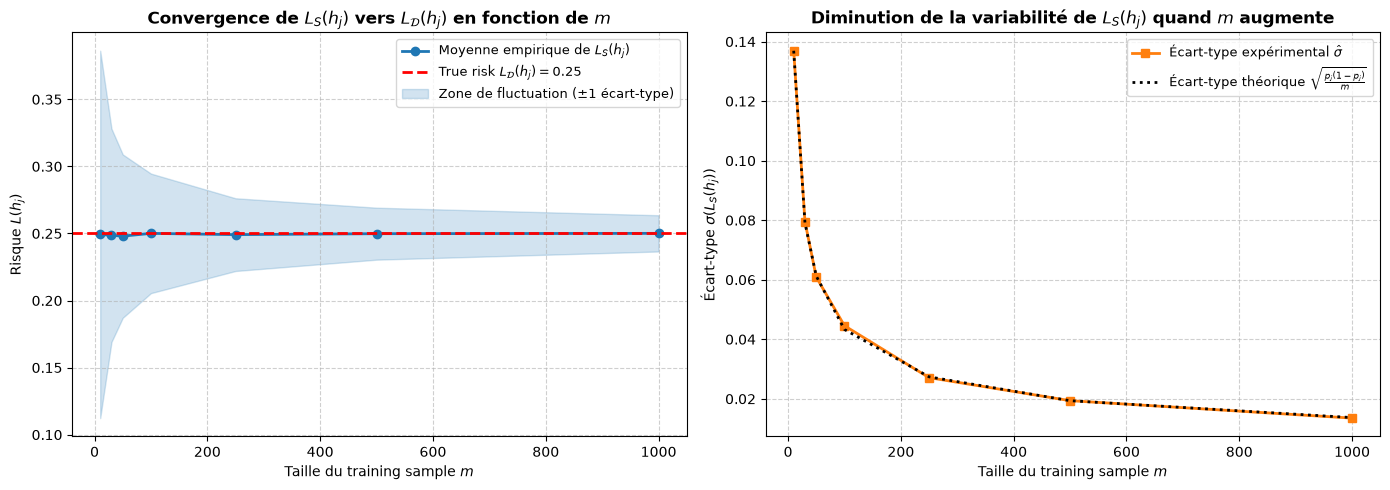

In [2]:
# (c) & (d) Visualisation 1 : Distribution de L_S(h_j) pour plusieurs tailles d'échantillon m
m_visu = [10, 30, 50, 100, 250, 1000]
fig, axes = plt.subplots(2, 3, figsize=(16, 8), sharex=True)
axes = axes.flatten()

for idx, m in enumerate(m_visu):
  ax = axes[idx]
  ls_simules, moy_emp, std_emp, _ = resultats_q1[m]

  # Histogramme de la distribution des risques empiriques L_S(h_j)
  ax.hist(
      ls_simules,
      bins=25,
      density=True,
      color='tab:blue',
      alpha=0.7,
      edgecolor='black',
      label=r'Distribution de $L_S(h_j)$',
  )

  # Ligne verticale rouge : Vrai risque L_D(h_j) = p_j
  ax.axvline(
      x=P_FIXE,
      color='red',
      linestyle='--',
      linewidth=2,
      label=rf'Vrai risque $p_j = {P_FIXE}$',
  )

  # Ligne verticale verte : Moyenne empirique sur les 5000 simulations
  ax.axvline(
      x=moy_emp,
      color='limegreen',
      linestyle=':',
      linewidth=2.5,
      label=rf'Moyenne $\hat{{\mu}} = {moy_emp:.3f}$',
  )

  ax.set_title(
      rf'$m = {m}$ | $\hat{{\mu}} = {moy_emp:.4f}$ | $\hat{{\sigma}} ='
      rf' {std_emp:.4f}$',
      fontsize=11,
      fontweight='bold',
  )
  ax.set_xlabel(r'Risque empirique $L_S(h_j)$')
  if idx % 3 == 0:
    ax.set_ylabel('Densité')
  ax.set_xlim(-0.05, 0.65)
  ax.grid(True, linestyle='--', alpha=0.5)

  if idx == 0:
    ax.legend(loc='upper right', fontsize=8.5)

plt.suptitle(
    rf'Distribution de empirical error $L_S(h_j)$ autour du true error $L_\mathcal{{D}}(h_j) = {P_FIXE}$ quand $m$ augmente',
    fontsize=14,
    fontweight='bold',
)
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

# Visualisation 2 : Évolution de la moyenne empirique et de l'écart-type (variabilité) en fonction de m
moyennes_tab = [resultats_q1[m][1] for m in m_tab]
std_exp_tab = [resultats_q1[m][2] for m in m_tab]
std_theo_tab = [resultats_q1[m][3] for m in m_tab]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Graphique de gauche : Moyenne empirique avec bande de +/- 1 écart-type
ax1.plot(
    m_tab,
    moyennes_tab,
    marker='o',
    color='tab:blue',
    linewidth=2,
    label=r'Moyenne empirique de $L_S(h_j)$',
)
ax1.axhline(
    y=P_FIXE,
    color='red',
    linestyle='--',
    linewidth=2,
    label=rf'True risk $L_\mathcal{{D}}(h_j) = {P_FIXE}$',
)
ax1.fill_between(
    m_tab,
    np.array(moyennes_tab) - np.array(std_exp_tab),
    np.array(moyennes_tab) + np.array(std_exp_tab),
    color='tab:blue',
    alpha=0.2,
    label=r'Zone de fluctuation ($\pm 1$ écart-type)',
)
ax1.set_title(
    r'Convergence de $L_S(h_j)$ vers $L_\mathcal{D}(h_j)$ en fonction de $m$',
    fontsize=12,
    fontweight='bold',
)
ax1.set_xlabel(r'Taille du training sample $m$')
ax1.set_ylabel(r'Risque $L(h_j)$')
ax1.grid(True, linestyle='--', alpha=0.6)
ax1.legend(fontsize=9.5)

# Graphique de droite : Diminution de l'écart-type (variabilité) avec m
ax2.plot(
    m_tab,
    std_exp_tab,
    marker='s',
    color='tab:orange',
    linewidth=2,
    label=r'Écart-type expérimental $\hat{\sigma}$',
)
ax2.plot(
    m_tab,
    std_theo_tab,
    linestyle=':',
    color='black',
    linewidth=2,
    label=r'Écart-type théorique $\sqrt{\frac{p_j(1-p_j)}{m}}$',
)
ax2.set_title(
    r'Diminution de la variabilité de $L_S(h_j)$ quand $m$ augmente',
    fontsize=12,
    fontweight='bold',
)
ax2.set_xlabel(r'Taille du training sample $m$')
ax2.set_ylabel(r'Écart-type $\sigma(L_S(h_j))$')
ax2.grid(True, linestyle='--', alpha=0.6)
ax2.legend(fontsize=9.5)

plt.tight_layout()
plt.show()

### Interprétation de la Question 1 : Empirical Risk as a Random Variable

**1. Comparaison entre la moyenne empirique et le vrai risque (estimateur sans biais) :**
   * On observe que pour toutes les tailles d'échantillons $m \in \{10, \dots, 1000\}$ (et pour toutes les valeurs de $p_k$ testées), la moyenne empirique des risques $\hat{\mu}$ (ligne verticale verte en pointillés) est quasiment confondue avec le vrai risque $L_\mathcal{D}(h_j) = p_j = 0.25$ (ligne verticale rouge).
   * Cela vérifie expérimentalement la propriété démontrée dans l'exercice 2 du TD1 : l'erreur empirique est une moyenne de variables aléatoires i.i.d. $\theta_i = \mathbb{1}\{h_j(x_i) \neq y_i\}$ d'espérance $\mathbb{E}[\theta_i] = L_\mathcal{D}(h_j) = p_j$. On a donc :
   $$\mathbb{E}_{S \sim \mathcal{D}^m}[L_S(h_j)] = \frac{1}{m}\sum_{i=1}^m \mathbb{E}[\theta_i] = L_\mathcal{D}(h_j) = p_j$$
   Le risque empirique $L_S(h_j)$ est donc un estimateur sans biais du true risk $L_\mathcal{D}(h_j)$, c'est-à-dire à force de répéter plusieurs fois l'expérience et en calculant l'empirical error, la moyenne des empirical error finit par donner le true risk.

**2. Évolution de la variabilité de $L_S(h_j)$ lorsque $m$ augmente :**
   * Pour un petit échantillon ($m = 10$ ou $m = 30$) : L'histogramme est très étalé (de $0.0$ jusqu'à $0.6$). L'écart-type vaut $\hat{\sigma} \approx 0.136$ pour $m=10$. Cela signifie que sur un seul tirage d'entraînement de petite taille, le risque empirique $L_S(h_j)$ peut facilement valoir proche de $0.0$ ou de $0.5$ par pur hasard, donnant une très mauvaise estimation du vrai risque $p_j = 0.25$.
   * Lorsque $m$ augmente ($m = 250, 500, 1000$) : L'histogramme se resserre de plus en plus en forme de cloche étroite autour de la valeur cible $p_j = 0.25$. Pour $m = 1000$, l'écart-type descend à $\hat{\sigma} \approx 0.0137$.
   * Explication théorique : Comme $E_j \sim \text{Binomial}(m, p_j)$ a pour variance $\text{Var}(E_j) = m p_j(1 - p_j)$, la variance de $L_S(h_j) = \frac{E_j}{m}$ vaut :
   $$\text{Var}(L_S(h_j)) = \frac{p_j(1 - p_j)}{m} \quad \implies \quad \sigma(L_S(h_j)) = \sqrt{\frac{p_j(1 - p_j)}{m}}$$
   Sur le deuxième graphique, la courbe expérimentale orange suit parfaitement la courbe théorique en $\frac{1}{\sqrt{m}}$. Conformément à la Loi des Grands Nombres, plus la taille d'échantillon $m$ augmente, plus la variance tend vers $0$ et plus le risque empirique $L_S(h_j)$ se rapproche du vrai risque $L_\mathcal{D}$.

## 2. Deviation Between Empirical and True Risk

Pour une hypothèse fixée $h_j$, on s'intéresse maintenant au Generalization Gap :
$$\vert{}L_S(h_j) - L_\mathcal{D}(h_j)\vert{}$$

Estimer expérimentalement la probabilité que cet écart dépasse un seuil de tolérance $\epsilon > 0$ (c'est-à-dire la probabilité que l'échantillon $S$ donne une mauvaise approximation du vrai risque de $h_j$) :
$$\Pr\left[\vert{}L_S(h_j) - L_\mathcal{D}(h_j)\vert{} > \epsilon\right]$$

D'après l'inégalité de Hoeffding, comme $L_S(h_j) = \frac{1}{m}\sum_{i=1}^m \theta_i$ est la moyenne de $m$ variables aléatoires indépendantes $\theta_i \in [0, 1]$ d'espérance $\mu = L_\mathcal{D}(h_j) = p_j$, cette probabilité est bornée supérieurement par :
$$\Pr\left[\vert{}L_S(h_j) - L_\mathcal{D}(h_j)\vert{} > \epsilon\right] \le 2 e^{-2 m \epsilon^2}$$

### Choix des paramètres :
* On fixe le seuil de précision à **$\epsilon = 0.05$** (on tolère un écart maximal de $5\%$ entre le risque empirique et le vrai risque).
* On garde l'hypothèse fixée avec $p_j = 0.25$ (et on affiche également sur le graphique le cas $p_k = 0.05$ et $p_k = 0.40$ de notre liste `p_tab = [0.05, 0.15, 0.25, 0.40, 0.70]` pour montrer l'influence de $p_j$ par rapport à la borne de Hoeffding).

Comparaison Probabilité expérimentale (p_j = 0.25) vs Borne de Hoeffding (epsilon = 0.05) :

m =   10 | Pr_exp(|L_S - L_D| > 0.05) = 0.4654 | Borne de Hoeffding = 1.9025
m =   30 | Pr_exp(|L_S - L_D| > 0.05) = 0.4056 | Borne de Hoeffding = 1.7214
m =   50 | Pr_exp(|L_S - L_D| > 0.05) = 0.3294 | Borne de Hoeffding = 1.5576
m =  100 | Pr_exp(|L_S - L_D| > 0.05) = 0.2198 | Borne de Hoeffding = 1.2131
m =  250 | Pr_exp(|L_S - L_D| > 0.05) = 0.0536 | Borne de Hoeffding = 0.5730
m =  500 | Pr_exp(|L_S - L_D| > 0.05) = 0.0080 | Borne de Hoeffding = 0.1642
m = 1000 | Pr_exp(|L_S - L_D| > 0.05) = 0.0000 | Borne de Hoeffding = 0.0135


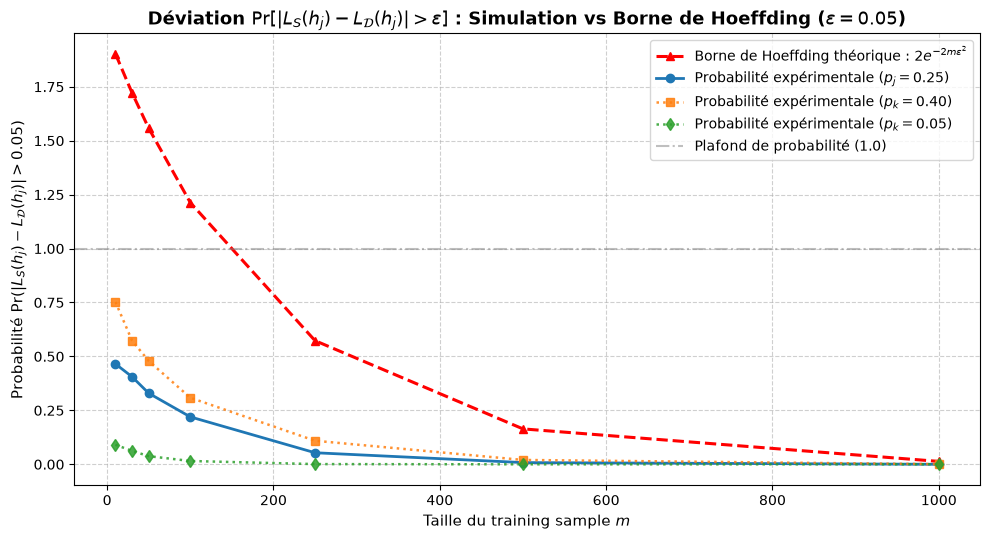

In [3]:
# Paramètre de précision epsilon choisi
EPSILON = 0.05  # Écart maximal toléré entre L_S(h_j) et L_D(h_j)

# On réutilise nos valeurs pour bien voir la décroissance exponentielle
proba_ecart_exp = (
    []
)  # Probabilité expérimentale Pr(|L_S(h_j) - L_D(h_j)| > epsilon) pour p_j = 0.25
borne_hoeffding_tab = []  # Borne théorique de Hoeffding : 2 * exp(-2 * m * epsilon^2)

print(
    f"Comparaison Probabilité expérimentale (p_j = {P_FIXE}) vs Borne de"
    f" Hoeffding (epsilon = {EPSILON}) :\n"
)

for m in m_tab:
  # Récupération des risques empiriques simulés à la Question 1 pour p_j = 0.25
  ls_simules = resultats_q1[m][0]

  # 1. Calcul de l'écart absolu |L_S(h_j) - L_D(h_j)| pour chaque sample simulé
  ecarts_absolus = np.abs(ls_simules - P_FIXE)

  # 2. Estimation de Pr(|L_S(h_j) - L_D(h_j)| > epsilon) : proportion des répétitions où l'écart dépasse epsilon
  proba_exp = np.mean(ecarts_absolus > EPSILON)
  proba_ecart_exp.append(proba_exp)

  # 3. Calcul de la borne théorique de Hoeffding : 2 * exp(-2 * m * epsilon^2)
  borne_theo = 2.0 * np.exp(-2.0 * m * (EPSILON**2))
  borne_hoeffding_tab.append(borne_theo)

  print(
      f"m = {m:4d} | Pr_exp(|L_S - L_D| > {EPSILON}) = {proba_exp:.4f} | Borne"
      f" de Hoeffding = {borne_theo:.4f}"
  )

# Calcul supplémentaire pour p = 0.05 et p = 0.40 afin d'enrichir la comparaison visuelle

proba_exp_p005 = []
proba_exp_p040 = []

for m in m_tab:

  # 1. Pour l'hypothèse avec un vrai risque de 0.05
  # Simulation de 5000 risques empiriques (L_S) pour cette taille m
  risques_simules_005 = simuler_risque_empirique(m, 0.05, N_REPETITIONS)
  # Calcul de l'écart absolu entre chaque risque simulé et le vrai risque (0.05)
  ecarts_005 = np.abs(risques_simules_005 - 0.05)
  # Calcul de la proportion que ces écarts dépasse notre seuil de tolérance (EPSILON)
  proportion_echec_005 = np.mean(ecarts_005 > EPSILON)
  # Ajout
  proba_exp_p005.append(proportion_echec_005)

  # 2. Pour l'hypothèse avec un vrai risque de 0.40
  risques_simules_040 = simuler_risque_empirique(m, 0.40, N_REPETITIONS)
  ecarts_040 = np.abs(risques_simules_040 - 0.40)
  proportion_echec_040 = np.mean(ecarts_040 > EPSILON)
  proba_exp_p040.append(proportion_echec_040)

# Visualisation : Probabilité expérimentale vs Borne de Hoeffding en fonction de m
plt.figure(figsize=(10, 5.5))

# Tracé de la borne théorique de Hoeffding
plt.plot(
    m_tab,
    borne_hoeffding_tab,
    marker="^",
    linestyle="--",
    color="red",
    linewidth=2.2,
    label=r"Borne de Hoeffding théorique : $2e^{-2m\epsilon^2}$",
)

# Tracé des probabilités expérimentales
plt.plot(
    m_tab,
    proba_ecart_exp,
    marker="o",
    linestyle="-",
    color="tab:blue",
    linewidth=2,
    label=rf"Probabilité expérimentale ($p_j = {P_FIXE}$)",
)
plt.plot(
    m_tab,
    proba_exp_p040,
    marker="s",
    linestyle=":",
    color="tab:orange",
    linewidth=1.8,
    alpha=0.85,
    label=r"Probabilité expérimentale ($p_k = 0.40$)",
)
plt.plot(
    m_tab,
    proba_exp_p005,
    marker="d",
    linestyle=":",
    color="tab:green",
    linewidth=1.8,
    alpha=0.85,
    label=r"Probabilité expérimentale ($p_k = 0.05$)",
)

# Ligne horizontale à 1.0 (probabilité maximale possible)
plt.axhline(
    y=1.0,
    color="gray",
    linestyle="-.",
    alpha=0.5,
    label="Plafond de probabilité (1.0)",
)

plt.title(
    r"Déviation $\Pr[|L_S(h_j) - L_\mathcal{D}(h_j)| > \epsilon]$ : Simulation"
    rf" vs Borne de Hoeffding ($\epsilon = {EPSILON}$)",
    fontsize=13,
    fontweight="bold",
)
plt.xlabel(r"Taille du training sample $m$", fontsize=11)
plt.ylabel(
    rf"Probabilité $\Pr(|L_S(h_j) - L_\mathcal{{D}}(h_j)| > {EPSILON})$",
    fontsize=11,
)
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend(fontsize=10)
plt.tight_layout()
plt.show()

### Interprétation de la Question 2 : Deviation Between Empirical and True Risk

**1. Évolution en fonction de $m$ (Décroissance exponentielle) :**
   * Aussi bien pour la courbe expérimentale que pour la courbe théorique de Hoeffding, la probabilité que le risque empirique $L_S(h_j)$ s'écarte du vrai risque $L_\mathcal{D}(h_j)$ de plus de $\epsilon = 0.05$ diminue très vite lorsque la taille de l'échantillon $m$ augmente.
   * Pour $p_j = 0.25$, la probabilité expérimentale passe de $0.4654$ (pour $m=10$) à $0.2198$ (pour $m=100$), puis tombe à $0.0000$ (pour $m=1000$). À partir de $m=1000$, il devient presque impossible que l'erreur empirique se trompe de plus de $5\%$ sur la vraie performance de l'hypothèse.

**2. La borne théorique de Hoeffding est-elle exacte ou conservatrice (conservative) ?**
   * La borne de Hoeffding est clairement conservatrice (pessimiste / large). Sur le graphique, la courbe rouge théorique $2e^{-2m\epsilon^2}$ est systématiquement située bien au-dessus des courbes expérimentales bleue, orange et verte.
   * Pourquoi est-elle aussi conservatrice ? On peut donner deux raisons :
     1. Indépendance vis-à-vis du vrai risque $p_j$ : La formule de Hoeffding $2e^{-2m\epsilon^2}$ utilise uniquement le fait que la fonction de coût est bornée dans $[a, b] = [0, 1]$. Elle ne dépend pas de $p_j$ et doit donc être valide dans le "pire des cas".
     2. Dépassement de $1$ pour les petits $m$ : Pour de petits échantillons ($m = 10, 30, 50$), la borne $2e^{-2m\epsilon^2}$ donne des valeurs supérieures à $1$ (par exemple $1.9025$ pour $m=10$ et $1.2131$ pour $m=100$ à cause du facteur $2$ devant l'exponentielle), alors qu'une probabilité ne peut jamais dépasser $1$.

## 3. From One Hypothesis to Uniform Convergence

Dans les questions précédentes, on a regardé l'écart $\vert{}L_S(h_j) - L_\mathcal{D}(h_j)\vert{}$ pour une *seule* hypothèse fixée $h_j$. 
Mais pour l'algorithme d'apprentissage ERM, on a besoin que cette approximation soit valable simultanément pour toutes les hypothèses de la classe $\mathcal{H} = \{h_1, \dots, h_K\}$. 

On définit donc la déviation maximale (maximum deviation) sur toute la classe d'hypothèses $\mathcal{H}$ pour un échantillon donné $S$ :
$$\Delta_S = \max_{h \in \mathcal{H}} \vert{}L_S(h) - L_\mathcal{D}(h)\vert{}$$

On souhaite estimer expérimentalement la probabilité de l'événement de convergence uniforme :
$$\Pr[\Delta_S > \epsilon] = \Pr\left[\max_{h \in \mathcal{H}} \vert{}L_S(h) - L_\mathcal{D}(h)\vert{} > \epsilon\right]$$

D'après le cours, la borne de convergence uniforme pour une classe d'hypothèses finie est donnée par :
$$\Pr\left[\max_{h \in \mathcal{H}} \vert{}L_S(h) - L_\mathcal{D}(h)\vert{} > \epsilon\right] \le 2 \vert{}\mathcal{H}\vert{} e^{-2 m \epsilon^2}$$

### Paramètres de l'expérience :
* Taille de la classe d'hypothèses : On fixe pour l'instant $\vert{}\mathcal{H}\vert{} = K = 10$ hypothèses, dont les vrais risques $p_1, \dots, p_K$ sont répartis uniformément entre $0.05$ et $0.70$.
* Précision voulue : On garde $\epsilon = 0.05$.
* Répétitions : `N_REPETITIONS = 5000`.

Simulation de l'Uniform Convergence (|H| = 10, epsilon = 0.05, 5000 répétitions) :

m =   10 | Pr_exp(max |L_S - L_D| > 0.05) = 1.0000 | Borne UC Théo = 19.0246
m =   30 | Pr_exp(max |L_S - L_D| > 0.05) = 0.9996 | Borne UC Théo = 17.2142
m =   50 | Pr_exp(max |L_S - L_D| > 0.05) = 0.9942 | Borne UC Théo = 15.5760
m =  100 | Pr_exp(max |L_S - L_D| > 0.05) = 0.9458 | Borne UC Théo = 12.1306
m =  250 | Pr_exp(max |L_S - L_D| > 0.05) = 0.5544 | Borne UC Théo = 5.7301
m =  500 | Pr_exp(max |L_S - L_D| > 0.05) = 0.1352 | Borne UC Théo = 1.6417
m = 1000 | Pr_exp(max |L_S - L_D| > 0.05) = 0.0062 | Borne UC Théo = 0.1348


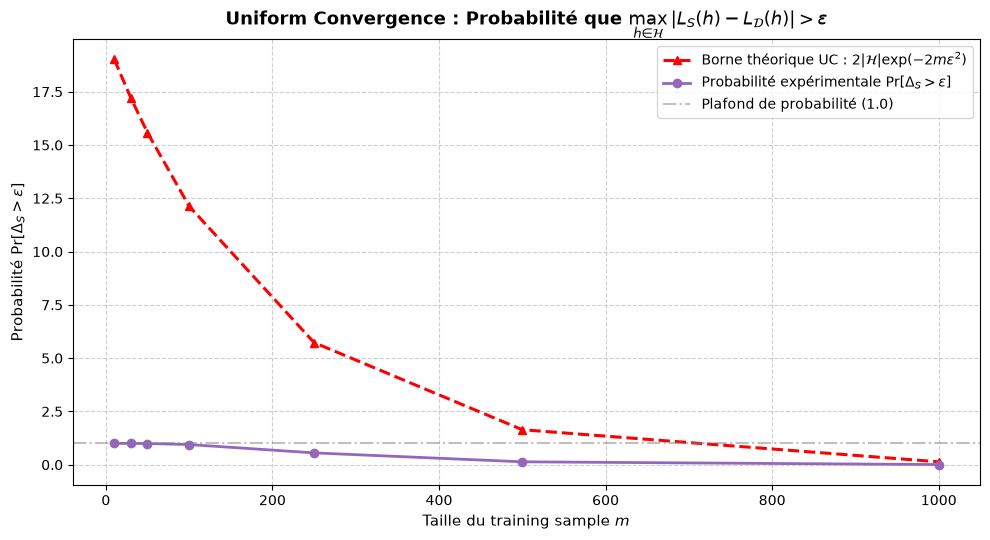

In [4]:
# Définition d'une classe d'hypothèses H de taille K finie
K_TAILLE_H = 10  # Nombre d'hypothèses dans H
# On génère des vrais risques p_j fixés pour chaque hypothèse de H (ex: répartis entre 0.05 et 0.70)
p_hypotheses_H = np.linspace(0.05, 0.70, K_TAILLE_H)

# Paramètres
eps_q3 = 0.05
proba_uc_exp = []
borne_uc_theo = []

print(
    f"Simulation de l'Uniform Convergence (|H| = {K_TAILLE_H}, epsilon ="
    f" {eps_q3}, {N_REPETITIONS} répétitions) :\n"
)

for m in m_tab:
  # Pour chaque répétition de Monte-Carlo, on simule les erreurs empiriques de TOUTES les hypothèses de H simultanément
  # shape de erreurs_emp_matrix : (N_REPETITIONS, K_TAILLE_H)
  erreurs_emp_matrix = np.zeros((N_REPETITIONS, K_TAILLE_H))

  for idx_h, pj in enumerate(p_hypotheses_H):
    erreurs_emp_matrix[:, idx_h] = simuler_risque_empirique(m, pj, N_REPETITIONS)

  # Calcul de la déviation maximale delta_S = max_h |L_S(h) - L_D(h)| pour chaque répétition
  # On soustrait le vecteur p_hypotheses_H à chaque ligne, on prend la valeur absolue, puis le max par ligne
  ecarts_matrix = np.abs(erreurs_emp_matrix - p_hypotheses_H)
  delta_s_tab = np.max(ecarts_matrix, axis=1)

  # Estimation expérimentale de Pr(delta_S > epsilon)
  proba_exp_uc = np.mean(delta_s_tab > eps_q3)
  proba_uc_exp.append(proba_exp_uc)

  # Borne théorique de convergence uniforme : 2 * |H| * exp(-2 * m * epsilon^2)
  borne_theo_uc = 2.0 * K_TAILLE_H * np.exp(-2.0 * m * (eps_q3**2))
  borne_uc_theo.append(borne_theo_uc)

  print(
      f"m = {m:4d} | Pr_exp(max |L_S - L_D| > {eps_q3}) = {proba_exp_uc:.4f} |"
      f" Borne UC Théo = {borne_theo_uc:.4f}"
  )

# Visualisation : Convergence uniforme expérimentale vs Borne théorique
plt.figure(figsize=(10, 5.5))

plt.plot(
    m_tab,
    borne_uc_theo,
    marker="^",
    linestyle="--",
    color="red",
    linewidth=2.2,
    label=r"Borne théorique UC : $2|\mathcal{{H}}|\exp(-2m\epsilon^2)$",
)
plt.plot(
    m_tab,
    proba_uc_exp,
    marker="o",
    linestyle="-",
    color="tab:purple",
    linewidth=2,
    label=r"Probabilité expérimentale $\Pr[\Delta_S > \epsilon]$",
)

plt.axhline(
    y=1.0, color="gray", linestyle="-.", alpha=0.5, label="Plafond de probabilité (1.0)"
)

plt.title(
    r"Uniform Convergence : Probabilité que $\max_{h \in \mathcal{H}}"
    r"|L_S(h) - L_\mathcal{D}(h)| > \epsilon$",
    fontsize=13,
    fontweight="bold",
)
plt.xlabel(r"Taille du training sample $m$", fontsize=11)
plt.ylabel(rf"Probabilité $\Pr[\Delta_S > \epsilon]$", fontsize=11)
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend(fontsize=10)
plt.tight_layout()
plt.show()

### Interprétation de la Question 3 : From One Hypothesis to Uniform Convergence

   * Contrairement à la Question 2 où l'on vérifiait Hoeffding pour *une seule* hypothèse fixée, l'algorithme ERM choisit son hypothèse $h_S$ parmi *toutes* les hypothèses possibles de $\mathcal{H}$ sur le même et unique échantillon $S$. 
   * Si un échantillon $S$ est malchanceux et donne une erreur empirique très élevée d'une seule des hypothèses au-delà de $\epsilon$, l'ERM risque de choisir cette mauvaise hypothèse. Pour garantir que l'ERM fonctionne, il faut donc que *toutes* les hypothèses de $\mathcal{H}$ simultanément respectent $|L_S(h) - L_\mathcal{D}(h)| \le \epsilon$, ce qui correspond exactement au critère de la déviation maximale $\Delta_S = \max_{h \in \mathcal{H}} |L_S(h) - L_\mathcal{D}(h)| \le \epsilon$.
   * Pour passer d'une hypothèse unique à toute la classe $\mathcal{H}$, la théorie utilise l'Union Bound). La probabilité qu'au moins une hypothèse échoue est inférieure ou égale à la *somme* des probabilités d'échec de chaque hypothèse. 
   * C'est de là que vient le facteur multiplicatif $|\mathcal{H}|$ dans la borne théorique $2 |\mathcal{H}| e^{-2 m \epsilon^2}$.

**Analyse des résultats :**
   * On observe que pour de petites tailles d'échantillons ($m = 10$ ou $m = 30$), la probabilité $\Pr[\Delta_S > \epsilon]$ est très proche de $1.0$ : sur de petits échantillons, il est quasi-certain qu'au moins une des $10$ hypothèses aura son erreur empirique qui s'écarte de plus de $5\%$ de son erreur vraie.
   * Lorsque $m$ est plus élevé ($m = 250, 500, 1000$), la probabilité de déviation maximale chute rapidement vers $0.0000$. 
   * Tout comme à la question précédente, la borne théorique reste très conservative (elle dépasse $1$ pour les petits $m$ à cause du terme $2|\mathcal{H}|$ devant l'exponentielle), mais elle confirme que l'uniform convergence est bien assurée dès que $m$ est suffisamment grand.

## 4. Effect of the Size of the Hypothesis Class

D'après la borne théorique de convergence uniforme vue en cours :
$$\Pr\left[\max_{h \in \mathcal{H}} \vert{}L_S(h) - L_\mathcal{D}(h)\vert{} > \epsilon\right] \le 2 \vert{}\mathcal{H}\vert{} e^{-2 m \epsilon^2}$$

Le terme de la taille de la classe d'hypothèses $\vert{}\mathcal{H}\vert{}$ apparaît en facteur multiplicatif.

### Choix des paramètres :
* Différentes tailles de classes $\vert{}\mathcal{H}\vert{}$ : On teste plusieurs valeurs : `tailles_H = [5, 10, 50, 100, 500]`.
* Précision voulue : On fixe $\epsilon = 0.05$.
* Répétitions : `N_REPETITIONS = 2000`.

Simulation de l'effet de la taille de H (epsilon = 0.05, 2000 répétitions) :

Terminé pour |H| =   5
Terminé pour |H| =  10
Terminé pour |H| =  50
Terminé pour |H| = 100
Terminé pour |H| = 500


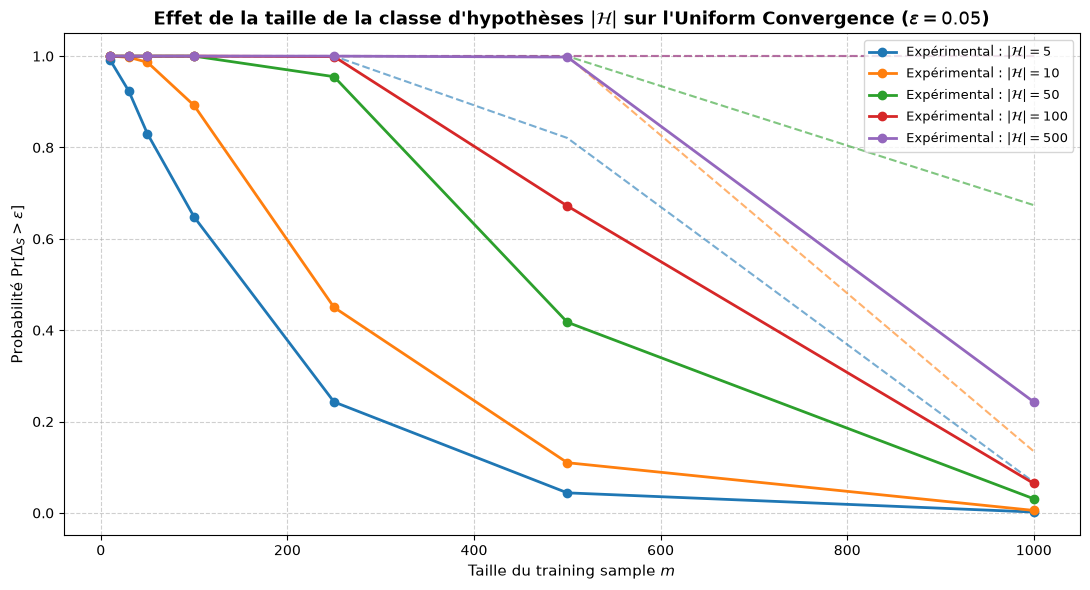

In [5]:
# Paramètres pour la Question 4
tailles_H = [5, 10, 50, 100, 500]
eps_q4 = 0.05
n_rep_q4 = 2000

# Dictionnaire pour stocker les résultats : clés = taille |H|, valeurs = liste des probabilités expérimentales pour chaque m
resultats_q4 = {}

print(
    f"Simulation de l'effet de la taille de H (epsilon = {eps_q4},"
    f" {n_rep_q4} répétitions) :\n"
)

for K in tailles_H:
  # On génère des vrais risques aléatoires mais fixes pour les K hypothèses
  p_class_H = np.linspace(0.02, 0.98, K)
  prob_exp_par_m = []

  for m in m_tab:
    erreurs_matrix = np.zeros((n_rep_q4, K))
    for idx_h, pj in enumerate(p_class_H):
      erreurs_matrix[:, idx_h] = simuler_risque_empirique(m, pj, n_rep_q4)

    # Calcul de la déviation maximale delta_S pour chaque répétition
    delta_s = np.max(np.abs(erreurs_matrix - p_class_H), axis=1)
    # Estimation de Pr(delta_S > epsilon)
    prob_exp = np.mean(delta_s > eps_q4)
    prob_exp_par_m.append(prob_exp)

  resultats_q4[K] = prob_exp_par_m
  print(f"Terminé pour |H| = {K:3d}")

# Visualisation : Probabilité Pr[Delta_S > epsilon] en fonction de m pour différentes tailles de |H|
plt.figure(figsize=(11, 6))

couleurs = ["tab:blue", "tab:orange", "tab:green", "tab:red", "tab:purple"]

for idx, K in enumerate(tailles_H):
  # Courbe expérimentale
  plt.plot(
      m_tab,
      resultats_q4[K],
      marker="o",
      linestyle="-",
      color=couleurs[idx],
      linewidth=2,
      label=rf"Expérimental : $|\mathcal{{H}}| = {K}$",
  )

  # Courbe théorique de la borne UC associée pour comparaison
  borne_associee = [
      min(1.0, 2.0 * K * np.exp(-2.0 * m * (eps_q4**2))) for m in m_tab
  ]
  plt.plot(
      m_tab,
      borne_associee,
      linestyle="--",
      color=couleurs[idx],
      alpha=0.6,
      linewidth=1.5,
  )

plt.title(
    r"Effet de la taille de la classe d'hypothèses $|\mathcal{H}|$ sur l'"
    rf"Uniform Convergence ($\epsilon = {eps_q4}$)",
    fontsize=13,
    fontweight="bold",
)
plt.xlabel(r"Taille du training sample $m$", fontsize=11)
plt.ylabel(rf"Probabilité $\Pr[\Delta_S > \epsilon]$", fontsize=11)
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend(fontsize=9.5, loc="upper right")
plt.tight_layout()
plt.show()

### Interprétation de la Question 4 : Effect of the Size of the Hypothesis Class

**How does increasing $|\mathcal{H}|$ affect uniform convergence ?**
   * Sur le graphique, on observe clairement que pour une taille d'échantillon $m$ fixée (par exemple $m = 100$ ou $m = 250$), la courbe de probabilité d'échec $\Pr[\Delta_S > \epsilon]$ se décale vers la droite lorsque $|\mathcal{H}|$ augmente (passant de $5$ à $500$ hypothèses).
   * Plus la classe d'hypothèses est grande, plus la probabilité qu'au moins une de ses hypothèses subisse un écart important entre risque empirique et risque vrai est élevée.

**Does a larger hypothesis class generally require more data ?**
   * Oui. En effet, pour maintenir la même garantie de fiabilité (par exemple pour que la probabilité d'échec descende sous les 5%, il faut un nombre d'exemples d'entraînement $m$ beaucoup plus grand si $|\mathcal{H}|$ est grand. 
   * C'est la traduction directe du terme $|\mathcal{H}|$ dans la borne de convergence uniforme $2|\mathcal{H}|e^{-2m\epsilon^2}$ : si $|\mathcal{H}|$ augmente, il faut compenser en augmentant $m$ pour que l'exponentielle négative annule cette augmentation.

**How does this relate to the $\log|\mathcal{H}|$ dependence appearing in finite-class sample-complexity
bounds ?**
   * On a la borne vue pour l'Uniform Convergence :
   $$m \ge \frac{\log(2|\mathcal{H}|/\delta)}{2\epsilon^2} = \frac{\log(2/\delta) + \log|\mathcal{H}|}{2\epsilon^2}$$
   * On constate que le nombre d'exemples requis $m$ ne dépend pas linéairement de la taille de la classe $|\mathcal{H}|$, mais plutôt de manière logarithmique ($\log|\mathcal{H}|$). C'est une excellente nouvelle en machine learning : cela signifie qu'on peut multiplier par 10 ou 100 le nombre d'hypothèses dans notre modèle, le nombre de données d'entraînement nécessaires n'aura besoin d'augmenter que de façon très modérée (additivement via son log).

## 5. Experimental Sample Complexity

### Paramètres fixés :
* Précision voulue : $\epsilon = 0.05$
* Confiance : $\delta = 0.05$ (on veut que $\Pr[\Delta_S > \epsilon] \le \delta$, c'est-à-dire une garantie de succès de $95\%$)
* Taille de la classe d'hypothèses : On fixe $|\mathcal{H}| = K = 10$

In [6]:
# Paramètres pour la Question 5
EPSILON_Q5 = 0.05
DELTA_Q5 = 0.05
K_Q5 = 10  # |H|

# 1. Calcul de la taille d'échantillon suffisante théorique
m_theorique = np.ceil(
    np.log(2.0 * K_Q5 / DELTA_Q5) / (2.0 * (EPSILON_Q5**2))
)
print(f"--- Résultats de la Question 5 ---")
print(
    f"Taille d'échantillon minimale suffisante théorique (Formule) : m >="
    f" {int(m_theorique)}"
)

# 2. Détermination expérimentale de la plus petite taille m testée dans m_tab pour laquelle Pr[Delta_S > epsilon] <= delta
m_experimental_trouve = None

print(f"\nRecherche de la taille d'échantillon expérimentale (N = 2000) :")
# On utilise un tableau de m plus fin pour être plus précis dans la recherche expérimentale
m_fin_tab = [10, 30, 50, 100, 250, 500, 750, 1000, 1500, 2000]

p_class_H_q5 = np.linspace(0.05, 0.45, K_Q5)
n_rep_q5 = 2000

for m in m_fin_tab:
  erreurs_matrix = np.zeros((n_rep_q5, K_Q5))
  for idx_h, pj in enumerate(p_class_H_q5):
    erreurs_matrix[:, idx_h] = simuler_risque_empirique(m, pj, n_rep_q5)

  delta_s = np.max(np.abs(erreurs_matrix - p_class_H_q5), axis=1)
  proba_echec = np.mean(delta_s > EPSILON_Q5)

  respecte_garantie = proba_echec <= DELTA_Q5
  print(
      f"m = {m:4d} | Pr(max |L_S - L_D| > {EPSILON_Q5}) = {proba_echec:.4f} |"
      f" Garantie respectée (<= {DELTA_Q5}) : {respecte_garantie}"
  )

  if respecte_garantie and m_experimental_trouve is None:
    m_experimental_trouve = m

print(
    f"\n-> Plus petite taille m testée validant la garantie PAC : m ="
    f" {m_experimental_trouve}"
)

--- Résultats de la Question 5 ---
Taille d'échantillon minimale suffisante théorique (Formule) : m >= 1199

Recherche de la taille d'échantillon expérimentale (N = 2000) :
m =   10 | Pr(max |L_S - L_D| > 0.05) = 1.0000 | Garantie respectée (<= 0.05) : False
m =   30 | Pr(max |L_S - L_D| > 0.05) = 0.9970 | Garantie respectée (<= 0.05) : False
m =   50 | Pr(max |L_S - L_D| > 0.05) = 0.9905 | Garantie respectée (<= 0.05) : False
m =  100 | Pr(max |L_S - L_D| > 0.05) = 0.9205 | Garantie respectée (<= 0.05) : False
m =  250 | Pr(max |L_S - L_D| > 0.05) = 0.4595 | Garantie respectée (<= 0.05) : False
m =  500 | Pr(max |L_S - L_D| > 0.05) = 0.0995 | Garantie respectée (<= 0.05) : False
m =  750 | Pr(max |L_S - L_D| > 0.05) = 0.0240 | Garantie respectée (<= 0.05) : True
m = 1000 | Pr(max |L_S - L_D| > 0.05) = 0.0060 | Garantie respectée (<= 0.05) : True
m = 1500 | Pr(max |L_S - L_D| > 0.05) = 0.0005 | Garantie respectée (<= 0.05) : True
m = 2000 | Pr(max |L_S - L_D| > 0.05) = 0.0000 | Garanti

### Interprétation de la Question 5 : Experimental Sample Complexity

   * En appliquant la formule théorique du cours pour $|\mathcal{H}| = 10$, $\epsilon = 0.05$ et $\delta = 0.05$ :
   $$m \ge \frac{\log(2 \times 10 / 0.05)}{2 \times (0.05)^2} = \frac{\log(400)}{0.005} \approx \frac{5.99}{0.005} \approx 1198 \text{ exemples}$$
Du côté de l'expérience, on constate que la probabilité d'échec descend sous les $\delta = 0.05$ dès que $m=750$ ce qui est nettement inférieur à la borne théorique de $1198$.


   * Tout comme nous l'avions observé pour la borne de Hoeffding à la Question 2, la borne de complexité d'échantillon issue de la convergence uniforme est conservative. Les raisons sont notamment :
1. L'inégalité de l'Union au pire des cas : La théorie additionne les risques d'échec de *toutes* les hypothèses en supposant qu'elles peuvent toutes mal se comporter en même temps dans le pire des cas, alors qu'en réalité, des erreurs peuvent être bien plus faibles.
2. Indépendance vis-à-vis de la distribution : La formule est universelle et s'applique à n'importe quelle distribution de probabilité et à n'importe quel ensemble de risques $p_j$, sans exploiter la structure spécifique de la classe testée.

* En conclusion, la borne théorique garantit mathématiquement qu'au-delà de $m \ge 1198$ exemples, on a bien la garantie, mais la réalité expérimentale montre qu'en pratique, un nombre de données plus faible peut suffir amplement pour réussir l'apprentissage.